# Tool calling



https://docs.langchain.com/oss/python/langchain/models#tool-calling




## 

##  basic tool calling flow between a user and a model:

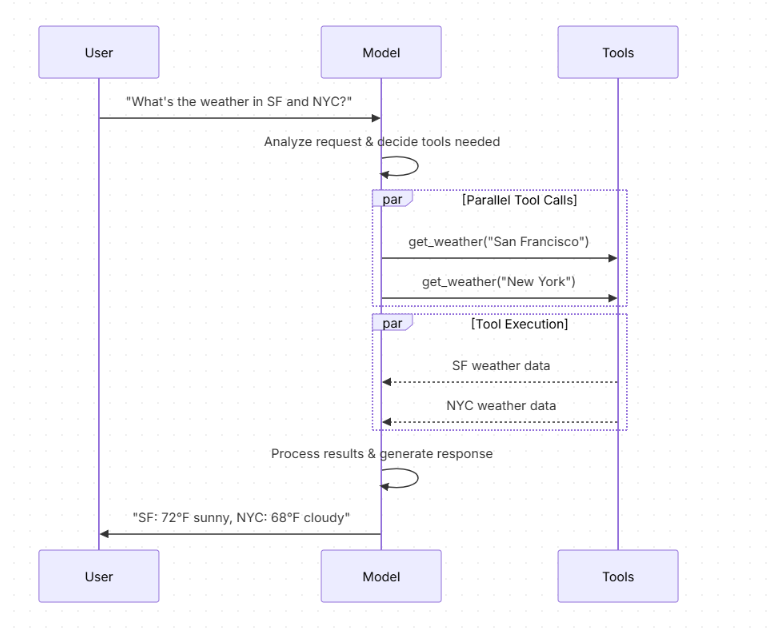

# 세팅  

In [ ]:
# Load environment variables in a file called .env
# API 키 설정 
import os
from dotenv import load_dotenv
load_dotenv(override=True)

True

# Binding user tools





In [1]:
from langchain.chat_models import init_chat_model

model = init_chat_model("gpt-5-mini")

In [8]:
from langchain.tools import tool  # 함수를 LangChain 도구로 만드는 데코레이터

# @tool: 함수를 도구 객체로 변환 (이름=함수명, 설명=독스트링, 입력 스키마=타입 힌트)
@tool
def get_weather(location: str) -> str:
    """Get the weather at a location."""  # 모델이 참고하는 도구 설명
    return f"It's sunny in {location}."   # 도구 실행 결과


# 모델에 도구 스키마를 연결한 새 모델 반환 (호출 시 tool_calls에 도구명·인자가 담김)
model_with_tools = model.bind_tools([get_weather])


In [9]:
# 도구가 바인딩된 모델 호출 (모델이 도구 필요 여부를 판단)
response = model_with_tools.invoke("What's the weather like in Boston?")

# tool_calls: 모델이 호출하기로 결정한 도구 목록 (실제 실행은 아직 안 됨)
for tool_call in response.tool_calls:
    # 모델이 요청한 도구 호출 내용 확인
    print(f"Tool: {tool_call['name']}")  # 호출할 도구 이름
    print(f"Args: {tool_call['args']}")  # 도구에 전달할 인자 (딕셔너리)

Tool: get_weather
Args: {'location': 'Boston, MA, USA'}


In [10]:
print(response)

content='' additional_kwargs={'refusal': None} response_metadata={'token_usage': {'completion_tokens': 155, 'prompt_tokens': 132, 'total_tokens': 287, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 128, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-ECkrK97w3lVZqiErWG0JxJaSzxxmN', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None} id='lc_run--01a00024-3945-7d61-be0a-2024abe60a74-0' tool_calls=[{'name': 'get_weather', 'args': {'location': 'Boston, MA, USA'}, 'id': 'call_vEz9YK7CAOKbluYgz7XKTdCV', 'type': 'tool_call'}] invalid_tool_calls=[] usage_metadata={'input_tokens': 132, 'output_tokens': 155, 'total_tokens': 287, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning'

# Lab 2: Tool execution loop


https://docs.langchain.com/oss/python/langchain/models#tool-execution-loop




In [11]:
# 모델에 도구를 바인딩 (도구를 여러 개 넣을 수도 있음)
model_with_tools = model.bind_tools([get_weather])

# 1단계: 모델이 도구 호출을 생성
messages = [{"role": "user", "content": "What's the weather in Boston?"}]
ai_msg = model_with_tools.invoke(messages)  # tool_calls가 담긴 AIMessage 반환
messages.append(ai_msg)                     # 대화 기록에 모델 응답 추가

# 2단계: 도구를 실제로 실행하고 결과를 수집
for tool_call in ai_msg.tool_calls:
    # tool_call 딕셔너리를 그대로 넘기면 ToolMessage 객체가 반환됨
    tool_result = get_weather.invoke(tool_call)
    messages.append(tool_result)  # 대화 기록에 도구 실행 결과 추가

# 3단계: 도구 결과를 포함한 전체 기록을 모델에 다시 전달해 최종 답변 생성
final_response = model_with_tools.invoke(messages)
print(final_response.text)
# "The current weather in Boston is 72°F and sunny."

It's sunny in Boston. Would you like current temperature, hourly forecast, or a 7-day outlook?


# Lab3  Parallel tool calls


https://docs.langchain.com/oss/python/langchain/models#parallel-tool-calls




In [ ]:
from langchain.tools import tool


@tool
def get_weather(location: str) -> str:
    """Get the weather at a location."""
    return f"It's sunny in {location}."

model_with_tools = model.bind_tools([get_weather])
# 모델은 도구 호출을 여러 개 생성할 수 있음 (병렬 도구 호출)
print(response.tool_calls)

messages = [{"role": "user", "content": "What's the weather in Boston and Tokyo?"}]
response = model_with_tools.invoke(messages)
messages.append(response)

# 방식 A: 이름으로 분기 (도구가 적을 때)
results = []
for tool_call in response.tool_calls:
    if tool_call["name"] == "get_weather":
        result = get_weather.invoke(tool_call)  
    else:
        raise ValueError(f"Unknown tool: {tool_call['name']}")
    results.append(result)


# 도구 실행 결과를 대화 기록에 추가한 뒤 모델에 다시 전달
messages.extend(results)
final_response = model_with_tools.invoke(messages)

print(final_response.text)

[{'name': 'get_weather', 'args': {'location': 'Boston, MA, USA'}, 'id': 'call_kNtz3PUcHM8coeX8QVLoCknV', 'type': 'tool_call'}, {'name': 'get_weather', 'args': {'location': 'Tokyo, Japan'}, 'id': 'call_BYUtRdN0pWZloHk7nMLXzV9i', 'type': 'tool_call'}]
Currently it's sunny in both locations:
- Boston, MA, USA: sunny.
- Tokyo, Japan: sunny.

Would you like more details (temperature, wind, humidity, hourly forecast, or a multi-day forecast)?


# Lab4  Parallel Many tool calls


https://docs.langchain.com/oss/python/langchain/models#parallel-tool-calls

In [12]:
from langchain.tools import tool


@tool
def get_weather(location: str) -> str:
    """Get the weather at a location."""
    return f"It's sunny in {location}."


@tool
def get_time(location: str) -> str:
    """Get the current time at a location."""
    return f"It's 3 PM in {location}."


tools = [get_weather, get_time]
model_with_tools = model.bind_tools(tools)

# 도구 이름으로 도구 객체를 찾기 위한 딕셔너리
tools_by_name = {t.name: t for t in tools}

messages = [{"role": "user", "content": "What's the weather in Boston and Tokyo?"}]
response = model_with_tools.invoke(messages)
messages.append(response)

# 방식 A: 이름으로 분기 (도구가 적을 때)
results = []
for tool_call in response.tool_calls:
    if tool_call["name"] == "get_weather":
        result = get_weather.invoke(tool_call)
    elif tool_call["name"] == "get_time":
        result = get_time.invoke(tool_call)
    else:
        raise ValueError(f"Unknown tool: {tool_call['name']}")
    results.append(result)

# 방식 B: 딕셔너리 조회 (도구가 많을 때 권장)
results = [tools_by_name[tc["name"]].invoke(tc) for tc in response.tool_calls]

# 도구 실행 결과를 대화 기록에 추가한 뒤 모델에 다시 전달
messages.extend(results)
final_response = model_with_tools.invoke(messages)
print(final_response.text)

Boston: It's sunny right now.

Tokyo: It's sunny right now.

Would you like temperatures, forecasts, or local times for either city?


# TavilySearchResults

In [18]:
from langchain_community.tools.tavily_search import TavilySearchResults  # Tavily 웹 검색 도구


# 고객지원 검색용 Tavily 인스턴스
support_search = TavilySearchResults(
    max_results=3,            # 검색 결과 최대 3개
    include_answer=True,      # 요약 답변 포함
    include_raw_content=True, # 원문 전체 포함
)

# 도구를 직접 호출 (딕셔너리로 query 전달)
results = support_search.invoke({"query": "현재 서울 날씨"})


In [19]:

# 반환값은 검색 결과 리스트 (각 항목은 url, content 등을 가진 딕셔너리)
for item in results:
    print(item["url"])
    print(item["content"][:200])  # 본문 앞 200자만 출력
    print("-" * 40)

https://www.aqi.in/weather/ko/south-korea/seoul/seoul
partly cloudyPartly Cloudy

Humidity Icon62%

UV Icon0

5.8kmph / ENESouth Korea flagGwangmyeongni, Gyeonggi

26 °C

partly cloudyPartly Cloudy

Humidity Icon62%

UV Icon0

5.8kmph / ENESouth Korea fl
----------------------------------------
https://www.msn.com/ko-kr/weather/forecast/in-%EC%84%9C%EC%9A%B8,%EB%8C%80%ED%95%9C%EB%AF%BC%EA%B5%AD
# 대한민국, 서울

현재 날씨

8:41 PM

28°C

대체로 흐림

체감

‎29°

대체로 흐립니다. 최저 기온은 25°입니다.

바람

연한 공기 (2 - 5 km/h)

연기 드리프트에 의해 표시되는 방향이지만 풍향계에 의해 표시되지는 않습니다.

5 km/h

습도

현재 온도에서 공기가 포함할 수 있는 최대 수분의 양에 비례하여 공기 중에 
----------------------------------------
https://www.accuweather.com/ko/kr/seoul/226081/current-weather/226081
# 서울특별시, 서울시

서울특별시

서울시

## 전 세계

전 세계

### 레이더 및 지도

### 동영상

### 악천후 기상

### 허리케인

# 현재 기상

AM 5:35

## 낮

폭염 주의보

최대 자외선 지수6.0 (해로움 (민감 그룹))

AccuLumen Brightness Index™3 (칙칙함)

바람남남동 7km/h

돌풍24k
----------------------------------------


## 모델에 바인딩해서 에이전트처럼 사용하는 예제

In [20]:
import os
from langchain_community.tools.tavily_search import TavilySearchResults
from langchain_openai import ChatOpenAI



support_search = TavilySearchResults(
    max_results=3,
    include_answer=True,
    include_raw_content=True,
)

model = ChatOpenAI(model="gpt-5-mini")
model_with_tools = model.bind_tools([support_search])  # 검색 도구를 모델에 연결

# 1단계: 모델이 검색이 필요한지 판단하고 도구 호출 생성
messages = [{"role": "user", "content": "현재 서울 날씨"}]
ai_msg = model_with_tools.invoke(messages)
messages.append(ai_msg)

# 2단계: 생성된 도구 호출을 실제로 실행
for tool_call in ai_msg.tool_calls:
    tool_result = support_search.invoke(tool_call)  # ToolMessage 반환
    messages.append(tool_result)

# 3단계: 검색 결과를 포함해 최종 답변 생성
final_response = model_with_tools.invoke(messages)
print(final_response.content)

방금 확인한 자료 기준으로 요약드릴게요.

- 기온: 약 26–28°C  
- 날씨: 대체로/부분적으로 흐림  
- 체감: 약 29°C (사이트별 차이 있음)  
- 습도: 약 60–70%  
- 바람: 3–7 km/h (약한 편)  
- 기압: 약 1004–1006 hPa  
- 강수 가능성: 지역 및 시간대에 따라 낮음~중간(일부 예보는 강수 확률 50% 이상 제시)

원하시면 실시간 시간별 예보(오늘 시간대별, 10일 전망)나 특정 구(예: 강남, 종로) 날씨도 바로 조회해 드릴게요. 어느 걸 원하시나요?


#